In [ ]:
import marimo as mo
import numpy as np
import matplotlib.pyplot as plt

![alt](public/task5.png)

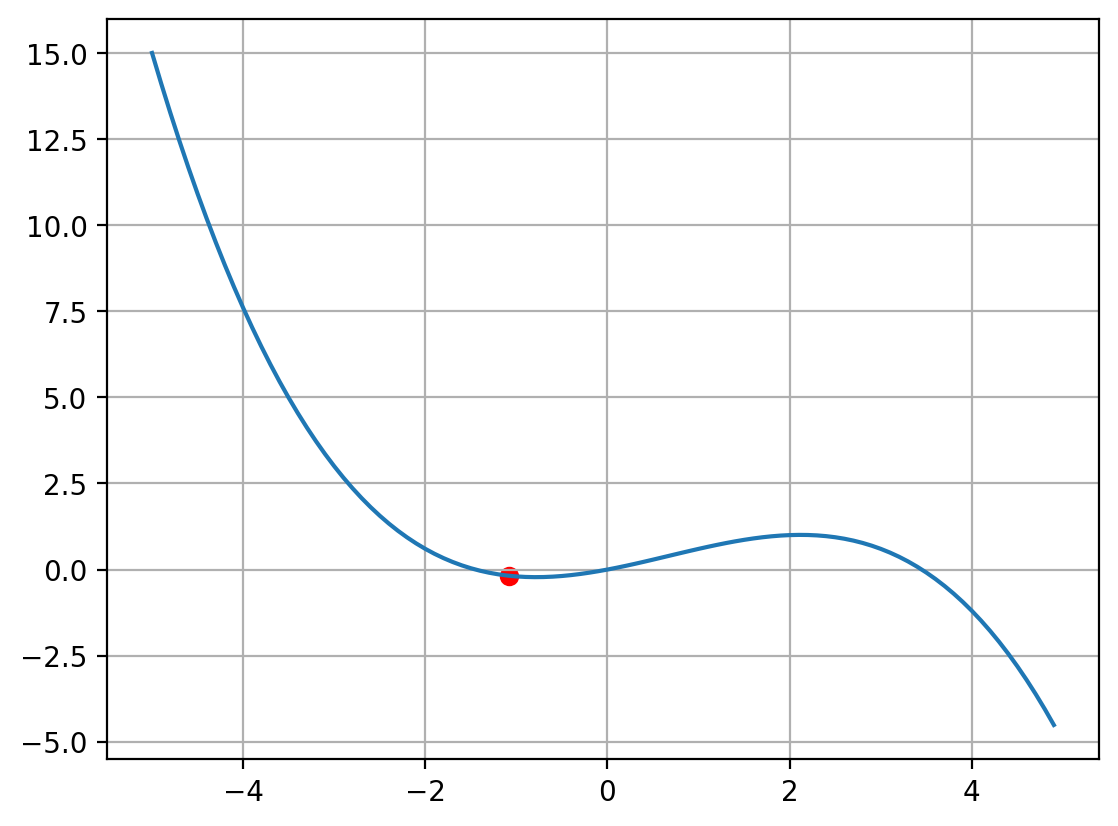

-1.0758987284245602


In [ ]:
def task5():
    def func(x):
        return 0.5 * x + 0.2 * x ** 2 - 0.1 * x ** 3


    def df(x):
        return 0.5 + 2 * 0.2 * x - 0.1 * 3 * x**2

    coord_x = np.arange(-5.0, 5.0, 0.1) # значения по оси абсцисс
    coord_y = func(coord_x) # значения по оси ординат (значения функции)

    eta = 0.01
    x = -4
    N = 200

    for i in range(N):
        x = x - eta * df(x)


    fig, ax = plt.subplots()
    ax.plot(coord_x, coord_y)
    ax.scatter(x, func(x), color='red')
    ax.grid()
    plt.show()

    print(x)

task5()


![alt](public/task6.png)

[ 4.98645739 -0.41780964  0.10273088  0.0317247 ] 0.13061463936073703


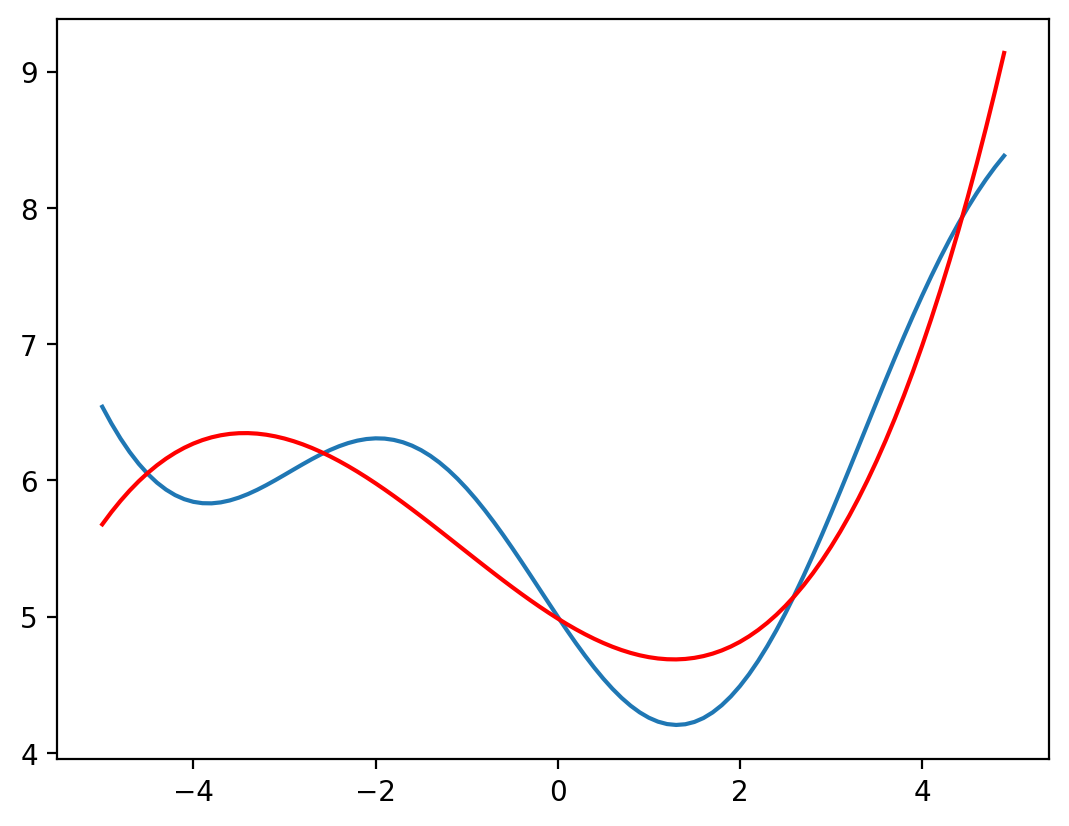

In [ ]:
def task6():
    # исходная функция, которую нужно аппроксимировать моделью a(x)
    def func(x):
        return 0.1 * x**2 - np.sin(x) + 5.

    def model(x, w):
        return w[0] + w[1] * x + w[2] * x**2 + w[3] * x**3

    def loss(x, w):
        return sum((model(xi, w) - func(xi)) ** 2 for xi in x) / len(x)

    def dw(x, w):
        res = 0
        for xi in x:
            s = np.array([1, xi, xi**2, xi**3])

            res += (w @ s - func(xi)) * s
        return 2 * res / len(x)
    # здесь объявляйте необходимые функции


    coord_x = np.arange(-5.0, 5.0, 0.1) # значения по оси абсцисс [-5; 5] с шагом 0.1
    coord_y = func(coord_x) # значения функции по оси ординат

    sz = len(coord_x)	# количество значений функций (точек)
    eta = np.array([0.1, 0.01, 0.001, 0.0001]) # шаг обучения для каждого параметра w0, w1, w2, w3
    w = np.array([0., 0., 0., 0.]) # начальные значения параметров модели
    N = 200 # число итераций градиентного алгоритма

    for i in range(N):
        w = w - eta * dw(coord_x, w)

    Q = loss(coord_x, w)

    print(w, Q)



    fig, ax = plt.subplots()
    ax.plot(coord_x, coord_y)
    ax.plot(coord_x, model(coord_x, w), color='red')
    plt.show()

task6()



